In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import warnings

plt.style.use('default')

In [2]:
with open(r'E:\satdata\Custom\yucatan_sst_chlor_cdomslope_ssl_bathy_2010-2019_v3.pkl', 'rb') as f:
    data = pickle.load(f)

df = data['data']
metadata = data['metadata']

In [19]:
metadata["bathymetry"]

array([[  -70.        ,   -68.969768  ,   -67.969768  , ...,
        -4575.299208  , -4565.97651249, -4552.3343366 ],
       [  -72.25452929,   -72.65788   ,   -72.128504  , ...,
        -4576.200936  , -4567.006848  , -4553.354816  ],
       [  -75.28724   ,   -75.66455804,   -75.        , ...,
        -4573.52014835, -4565.719608  , -4553.677408  ],
       ...,
       [-3771.17756   , -3772.        , -3769.38092   , ...,
        -1293.31544   , -1304.380488  , -1468.66918194],
       [-3774.57532982, -3773.672592  , -3772.        , ...,
        -1299.41474387, -1403.1584367 , -1507.78488001],
       [-3777.855392  , -3778.22303794, -3773.990064  , ...,
        -1330.72262805, -1432.82084253, -1505.82255973]], shape=(250, 250))

In [10]:
zero_count = sum(
    np.count_nonzero(arr == 0) for arr in df["cdom"]
)

zero_count

np.int64(20)

In [12]:
zero_count = sum(
    np.count_nonzero(arr == 0) for arr in df["cdom_slope_300_600"]
)

zero_count

np.int64(0)

In [4]:
nan_count = sum(
    np.count_nonzero(np.isnan(arr))
    for arr in df["cdom"]
)

nan_count

np.int64(192887720)

In [7]:
nan_count = sum(
    np.count_nonzero(np.isnan(arr))
    for arr in df["cdom_slope_275_295"]
)

nan_count

np.int64(167776175)

In [8]:
nan_count = sum(
    np.count_nonzero(np.isnan(arr))
    for arr in df["cdom_slope_300_600"]
)

nan_count

np.int64(167776175)

In [30]:
import math

C:\Users\Makai\AppData\Local\Temp\ipykernel_31956\2661829480.py:3: RuntimeWarning: divide by zero encountered in log
  day = np.log(-day)
C:\Users\Makai\AppData\Local\Temp\ipykernel_31956\2661829480.py:3: RuntimeWarning: invalid value encountered in log
  day = np.log(-day)


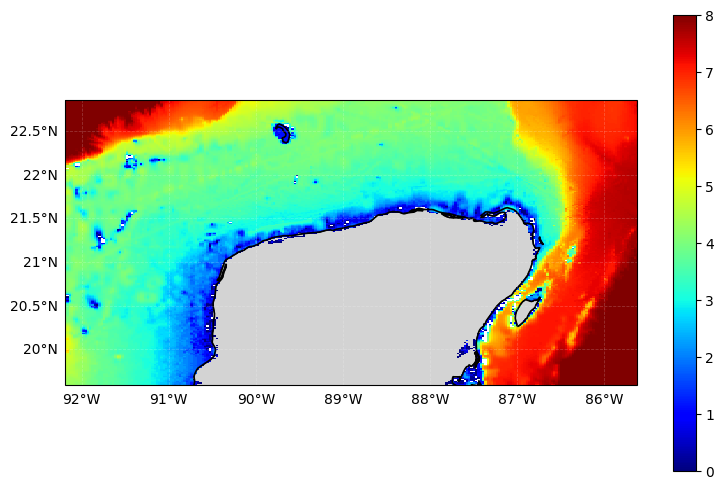

In [40]:
# day = df["cdom_slope_300_600"][pd.Timestamp("01-01-2018")][1]
day = metadata["bathymetry"]
day = np.log(-day)

map_data = np.asarray(day, dtype=float)

lon_centers = np.array(metadata["lon_centers"])
lat_centers = np.array(metadata["lat_centers"])
map_data.shape == (len(lat_centers), len(lon_centers))

lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers)
fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()})

ax.set_extent(
    [lon_centers.min(), lon_centers.max(), lat_centers.min(), lat_centers.max()],
    crs=ccrs.PlateCarree(),
)

mesh = ax.pcolormesh(
    lon_grid, lat_grid, map_data,
    cmap="jet", transform=ccrs.PlateCarree(), shading="auto"
)

ax.add_feature(cfeature.LAND, facecolor="lightgray", edgecolor="black", linewidth=0.8)
ax.add_feature(cfeature.COASTLINE, linewidth=1.2)

gl = ax.gridlines(draw_labels=True, linewidth=0.6, color="white", alpha=0.2, linestyle="--")
gl.top_labels = False
gl.right_labels = False

cbar = fig.colorbar(mesh, ax=ax, orientation="vertical", shrink=0.8, pad=0.05)

mesh.set_clim(0, 8)

plt.tight_layout()
plt.show()